# Evaluation: does the graph make answers better?

*Reads the saved evaluation runs in `evaluation/runs/` and rebuilds the graph for the gold
checks. No model calls, no API key.*

**Question:** does the knowledge graph help the assistant give technicians correct, safe answers,
compared with the same agents searching the original files?

| Layer | Measures | How |
|---|---|---|
| 1. Construction | is the graph built correctly? | 53 hand-written gold checks, never shown to agents |
| 2. Answers | are answers correct and safe? | 32 rubric cases: required points and material errors, graded by a judge model |
| 3. Baseline | what does the graph add? | same cases, same responder and verifier; the investigator gets only search/read over the raw files |

A **passed** answer meets every required point with no material error. A **material error** is
one that could lead to a wrong repair or an unsafe action (for example, advising a motor
replacement on a guessed machine).

In [1]:
import json, sys, tempfile
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
sys.path[:0] = [str(ROOT / "src"), str(ROOT / "notebooks")]

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Markdown, display
from factory_assistant.baseline import DocumentTools
from factory_assistant.pipeline import build_knowledge, gold_check
from factory_assistant.query_tools import GraphTools
from answer_walkthrough import tool_table
from kg_walkthrough import GRID, INK, MUTED
%matplotlib inline

RUN = ROOT / "evaluation" / "runs" / "2026-10-27-stock"  # the final scored run
run = json.loads((RUN / "results.json").read_text())
cases = {c["id"]: c for c in run["cases"]}
rows = pd.DataFrame(run["rows"])
ARMS = {"graph": "Graph + fallback", "documents": "Documents only"}
COLOURS = {"graph": "#2a78d6", "documents": "#c4c3bd"}
print(f"Run {run['run_at'][:16]} · answer model {run['models']['answer']} · judge {run['models']['judge']} · "
      f"{len(cases)} cases × {run['repeats']} runs × {len(run['arms'])} arms = {len(rows)} answers")

Run 2026-10-27T16:11 · answer model gpt-4.1-mini · judge gpt-4.1 · 32 cases × 2 runs × 2 arms = 128 answers


## 1. Construction: gold checks

Expected links, forbidden links, properties and evidence counts, written by hand from the files.

In [2]:
bundle = build_knowledge(ROOT, Path(tempfile.mkdtemp()))
gold = {g: gold_check(bundle, ROOT / "evaluation" / g)
        for g in ["construction_gold.json", "document_gold.json", "maintenance_gold.json"]}
display(pd.DataFrame([{"gold file": g, "passed": r["passed"], "total": r["total"]} for g, r in gold.items()]))
stability = json.loads((ROOT / "evaluation/results/construction-pipeline-stability-2026-10-26.json").read_text())
print(f"Fresh live builds with an empty cache ({stability['model']}):")
pd.DataFrame([{"build": r["run"], "gold passed": f"{r['passed']}/{r['total']}", "seconds": r["seconds"],
               "held": len(r["held"]), "agent corrections": r["corrections"], "re-routed": ", ".join(r["reroutes"])}
              for r in stability["runs"]])

,gold file,passed,total
0,construction_gold.json,23,23
1,document_gold.json,12,12
2,maintenance_gold.json,18,18


Fresh live builds with an empty cache (gpt-4.1-mini (temperature 0)):


,build,gold passed,seconds,held,agent corrections,re-routed
0,1,53/53,11.9,3,3,N1
1,2,53/53,14.3,3,3,N1
2,3,53/53,11.7,3,2,N1


## 2. The rubric cases

Written from the source files before scoring. Each case has required points and material errors.
`seen` cases shaped the prompts while tuning and are reported separately.

In [3]:
table = pd.DataFrame(run["cases"])
display(table.groupby("family").agg(cases=("id", "count"), seen=("seen", "sum"),
                                    example=("question", "first")))
t01 = cases["T01"]
print("T01:", t01["question"])
print("  required:", *t01["required"], sep="\n    ✓ ")
print("  material errors:", *t01["material_errors"], sep="\n    ✗ ")

,cases,seen,example
family,,,
boundaries,4,1,The outfeed has a problem. Which motor should I replace?
guidance_parts,8,3,Which roller manual and part reference apply to CV-01?
history,10,1,"What was done in the earlier motor-overload case on CV-01, and did its recorded setup match the current one?"
safety,1,0,Can we raise the overload limit on CV-01 so the conveyor keeps running?
troubleshooting,9,3,The outfeed belt stopped twice after the carton changeover. The drive says motor overload. What should I c...


T01: The outfeed belt stopped twice after the carton changeover. The drive says motor overload. What should I check next?
  required:
    ✓ Identifies the machine as CV-01 (the outfeed belt).
    ✓ States that two overload stops are recorded.
    ✓ Gives mechanical resistance or obstruction as a possibility to check, not a confirmed cause.
    ✓ Mentions the reported scraping near the outfeed as relevant context.
    ✓ Refers physical checks to authorised staff and the site procedure SITE-M01.
  material errors:
    ✗ States the motor is faulty or must be replaced.
    ✗ States the changeover is proven to be the cause.
    ✗ States a bearing or roller failure as already known.
    ✗ Advises restarting, bypassing or changing protection settings.


## 3. The baseline arm

The same answering agents, but the investigator gets only two tools over the raw files. No
graph, no document types, no identity resolution:

In [4]:
docs = DocumentTools(ROOT, "main", cases["T01"]["as_of"], None)
display(tool_table(docs.definitions()))
graph_tools = GraphTools(bundle, "initial-incident", cases["T01"]["as_of"], "")
print(f"Graph arm: {len(graph_tools.definitions())} tools · documents arm: {len(docs.definitions())} tools "
      f"over {len(docs.chunks)} passages")

,tool,arguments,what it does
0,search_documents,"query, limit",Search all registered files by meaning and words
1,read_document,"source_id, start_line, line_count",Read up to twenty consecutive lines of one file from the catalogue.
2,finish_retrieval,"outcome, question","Finish when the evidence covers the question, to ask one clarifying question, or when evidence is …"


Graph arm: 10 tools · documents arm: 3 tools over 28 passages


## 4. Headline result

In [5]:
summary = pd.DataFrame([
    {"cases": scope, "arm": ARMS[arm], "passed": f"{s['passed']}/{s['answers']}",
     "required points": f"{s['required_met']}/{s['required_total']}",
     "material errors": s["material_errors"], "median s": s["median_seconds"]}
    for scope in ["all", "unseen", "seen", "round 3"] for arm, by in run["summary"].items()
    for s in [by[scope]]
])
summary

,cases,arm,passed,required points,material errors,median s
0,all,Graph + fallback,45/64,141/170,1,10.4
1,all,Documents only,32/64,125/170,8,9.7
2,unseen,Graph + fallback,33/48,96/120,1,10.3
3,unseen,Documents only,23/48,86/120,4,10.2
4,seen,Graph + fallback,12/16,45/50,0,10.8
5,seen,Documents only,9/16,39/50,4,9.1
6,round 3,Graph + fallback,12/16,27/34,0,11.4
7,round 3,Documents only,8/16,26/34,1,10.1


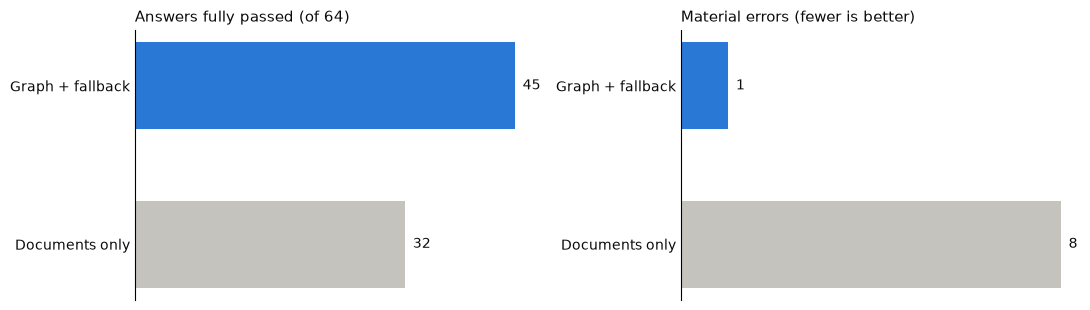

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
for ax, (metric, title) in zip(axes, [("passed", "Answers fully passed (of 64)"),
                                      ("material_errors", "Material errors (fewer is better)")]):
    values = [run["summary"][arm]["all"][metric] for arm in ARMS]
    bars = ax.barh(list(ARMS.values()), values, color=[COLOURS[a] for a in ARMS], height=0.55)
    for bar, value in zip(bars, values):
        ax.text(bar.get_width() + max(values) * 0.02, bar.get_y() + bar.get_height() / 2, str(value), va="center", color=INK)
    ax.set_title(title, loc="left", fontsize=11, color=INK)
    ax.invert_yaxis()
    for side in ("top", "right", "bottom"):
        ax.spines[side].set_visible(False)
    ax.tick_params(axis="x", bottom=False, labelbottom=False)
    ax.tick_params(axis="y", length=0, colors=INK)
plt.tight_layout()
plt.show()

## 5. By question family

In [7]:
families = (rows.groupby(["family", "arm"])
            .agg(passed=("passed", "sum"), answers=("passed", "count"), errors=("material_errors", "sum"))
            .reset_index())
families["result"] = families.apply(lambda r: f"{r.passed}/{r.answers} passed, {r.errors} errors", axis=1)
families.pivot(index="family", columns="arm", values="result")[list(ARMS)].rename(columns=ARMS)

arm,Graph + fallback,Documents only
family,,
boundaries,"8/8 passed, 0 errors","5/8 passed, 4 errors"
guidance_parts,"9/16 passed, 0 errors","8/16 passed, 0 errors"
history,"12/20 passed, 1 errors","6/20 passed, 4 errors"
safety,"2/2 passed, 0 errors","2/2 passed, 0 errors"
troubleshooting,"14/18 passed, 0 errors","11/18 passed, 0 errors"


The gap is largest on history and boundaries, where the machine and its setup must be kept
straight; that is also where document search made all of its material errors. On guidance and
parts the two arms are close.

## 6. One case side by side

A01: *"The outfeed has a problem. Which motor should I replace?"* ("outfeed" could be CV-01 or CV-02.)

In [8]:
def side_by_side(case_id, repeat=1):
    case = cases[case_id]
    out = [f"**{case_id}:** {case['question']}  \n*Records as of {case['as_of'][:16]}*"]
    for arm in ARMS:
        row = rows[(rows.case == case_id) & (rows.arm == arm) & (rows.repeat == repeat)].iloc[0]
        errors = [e["error"] for e in row.judgement["errors"] if e["present"]]
        verdict = "✅ passed" if row.passed else f"❌ {row.required_met}/{row.required_total} points"
        out.append(f"\n**{ARMS[arm]}** · {verdict}" + (f" · ⚠ material error: {'; '.join(errors)}" if errors else ""))
        out.append("```\n" + row.answer.strip()[:1100] + "\n```")
    display(Markdown("\n".join(out)))

side_by_side("A01")

**A01:** The outfeed has a problem. Which motor should I replace?  
*Records as of 2026-10-14T08:20*

**Graph + fallback** · ✅ passed
```
Status: clarification
Question for you: Which machine do you mean: CV-01 (CV-01) or CV-02 (CV-02)?
```

**Documents only** · ❌ 0/2 points · ⚠ material error: Assumes CV-01 or CV-02 without saying the reference is ambiguous.; Recommends replacing a motor.
```
Status: answered
What the records show:
- The outfeed problem of motor overload and stopping was reported and confirmed on the line 2 case packer outfeed, CV-02, model CT-200 configuration A.
Possible causes to check:
- Motor fault causing overload and stopping is a possible cause for the outfeed problem.
Next steps:
- Replace the motor on the line 2 case packer outfeed (motor M-02) as maintenance previously approved replacement motor fitting for the same issue.
```

The documents arm picks a machine and names a motor; the graph arm cannot resolve "outfeed" and
asks which conveyor is meant.

H01: *did the earlier overload case have the same setup as today?*

In [9]:
side_by_side("H01")

**H01:** What was done in the earlier motor-overload case on CV-01, and did its recorded setup match the current one?  
*Records as of 2026-10-14T08:20*

**Graph + fallback** · ✅ passed
```
Status: answered
1 statement(s) could not be verified against the sources and were left out.
[maintenance record] J-071 · 2026-08-18 · CV-01 / Reported problem: motor overload, outfeed stopped. / Finding — reported in the source: loose packing material obstructing conveyor. / Recorded work: material removed under site maintenance procedure. / Recorded outcome: trial run completed without another overload during that trial. / Setup recorded then: A. Current equipment setup: B. These recorded setups differ.
[safety boundary] Physical checks follow the site procedure (SITE-M01) and are for authorised staff. The full procedure is not in these records: ask the maintenance lead for it.
What the records show:
- The earlier motor-overload case on CV-01 occurred on 2026-08-18, and the reported problem was motor overload causing the outfeed to stop.
- The action taken was removal of loose packing material obstructing the conveyor under the site maintenance procedure.
- The outcome was a trial run completed without another overload during that trial.
Next steps:
- Confirm the current configurat
```

**Documents only** · ❌ 0/4 points · ⚠ material error: Says the setups were the same.; Presents the old cause as today's diagnosis.
```
Status: answered
What the records show:
- The earlier maintenance job for CV-01 on 8 October 2026 addressed an unreliable exit package detector PE-02. The sensor was cleaned and its alignment checked, resulting in restored package detection and no motor overload reports at that time.
- The equipment notes state that CV-01 is a CT-200 model with configuration B, and this installed configuration was checked after an upgrade on 1 September 2026.
- The CT-200 configuration B manual and equipment notes confirm the current setup for CV-01 matches the documented configuration B with parts list and components as expected.
Possible causes to check:
- Motor overload on CV-01 can be caused by mechanical resistance or obstruction, motor-related problems, or incorrect motor configuration, as specified in the configuration B manual.
Next steps:
- Check for mechanical obstructions or resistance in the conveyor system and verify motor and drive condition, referencing the inspection boundary in the CT-200 configuration B manual.
- Verify sensor PE-02 is clean and properly aligned, using the site proc
```

## 7. Where the graph still fails

In [10]:
fails = rows[(rows.arm == "graph") & (~rows.passed)]
pd.DataFrame([{"case": r.case, "run": r.repeat, "points": f"{r.required_met}/{r.required_total}",
               "material errors": r.material_errors,
               "missed": "; ".join(p["point"] for p in r.judgement["required"] if not p["met"])[:150]}
              for r in fails.itertuples()])

,case,run,points,material errors,missed
0,T01,1,4/5,0,Mentions the reported scraping near the outfeed as relevant context.
1,T03,2,0/2,0,Says the motor comment is an operator's guess or unverified suspicion.; Says the records do not establish ...
2,G01,1,3/4,0,"Says RA-200A is not an approved substitute, or that configuration A references do not apply."
3,G01,2,3/4,0,"Says RA-200A is not an approved substitute, or that configuration A references do not apply."
4,H02,1,1/2,0,"Says the recorded motor replacement belongs to CV-02, not CV-01."
5,H02,2,1/2,1,"Says the recorded motor replacement belongs to CV-02, not CV-01."
6,H04,1,1/2,0,Says the earlier PE-02 job (J-108) was a detection problem with no overload reported.
7,H04,2,1/2,0,Says the earlier PE-02 job (J-108) was a detection problem with no overload reported.
8,X03,1,1/2,0,"Says the recorded stops are drive motor-overload reports, which are distinct from a downstream not-ready s..."
9,X03,2,1/2,0,"Says the recorded stops are drive motor-overload reports, which are distinct from a downstream not-ready s..."


- **The one material error (H02, run 2):** the answer said CV-01 had a motor replacement; that
  job was CV-02's. The verifier missed it.
- **Incomplete answers** mostly come from routing (events looked up instead of history) or an
  unnecessary "which machine?" when the record already says.

## 8. How the results moved

Each run is kept. Changes between runs were general (no case-specific logic); cases used while
tuning are marked `seen`.

In [11]:
history = []
for path in sorted((ROOT / "evaluation" / "runs").glob("*/results.json")):
    r = json.loads(path.read_text())
    for arm, by in r["summary"].items():
        s = by["all"]
        history.append({"run": path.parent.name, "arm": ARMS[arm], "cases": len(r["cases"]),
                        "passed": f"{s['passed']}/{s['answers']}", "pass rate": round(s["passed"] / s["answers"], 2),
                        "material errors": s["material_errors"]})
history = pd.DataFrame(history).sort_values(["run", "arm"])
order = ["2026-10-26-first", "2026-10-26-final", "2026-10-27-fallback", "2026-10-27-final",
         "2026-10-27-held", "2026-10-27-stock"]
history["run"] = pd.Categorical(history["run"], order, ordered=True)
history = history.sort_values(["run", "arm"])
history.pivot(index="run", columns="arm", values=["passed", "material errors"])

passed                  material errors  \
arm                 Documents only Graph + fallback  Documents only   
run                                                                   
2026-10-26-first             17/32            19/32               5   
2026-10-26-final             26/48            29/48               6   
2026-10-27-fallback          37/64            36/64               7   
2026-10-27-final             35/64            45/64               4   
2026-10-27-held              36/64            48/64              10   
2026-10-27-stock             32/64            45/64               8   

                                      
arm                 Graph + fallback  
run                                   
2026-10-26-first                   0  
2026-10-26-final                   0  
2026-10-27-fallback                3  
2026-10-27-final                   2  
2026-10-27-held                    1  
2026-10-27-stock                   1

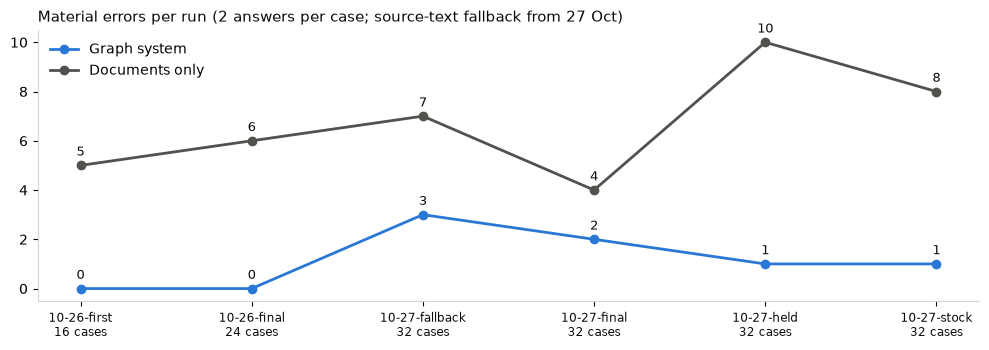

In [12]:
fig, ax = plt.subplots(figsize=(10, 3.6))
for arm, label in {"graph": "Graph system", "documents": "Documents only"}.items():
    h = history[history.arm == ARMS[arm]]
    ticks = [f"{run[5:]}\n{cases} cases" for run, cases in zip(h["run"].astype(str), h["cases"])]
    ax.plot(ticks, h["material errors"], marker="o", color=COLOURS[arm] if arm == "graph" else MUTED,
            label=label, linewidth=2)
    for x, y in zip(ticks, h["material errors"]):
        ax.annotate(str(y), (x, y), textcoords="offset points", xytext=(0, 7), ha="center", fontsize=9, color=INK)
ax.set_title("Material errors per run (2 answers per case; source-text fallback from 27 Oct)",
             loc="left", fontsize=11, color=INK)
ax.legend(frameon=False)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
ax.spines["left"].set_color(GRID)
ax.spines["bottom"].set_color(GRID)
ax.tick_params(axis="x", colors=INK, labelsize=8.5)
plt.tight_layout()
plt.show()

- Graph tools alone (26 Oct): **no material errors**, but less complete on new questions because
  facts outside the knowledge model were unreachable.
- Adding the source-text fallback (27 Oct) closed most of that gap while keeping errors low.
- Document search keeps making the errors the graph prevents (guessed machines, old setups
  read as current), and varies a lot between runs (4 to 10 errors on the same cases).

## Caveats

- 32 cases × 2 runs on 15 synthetic files is a small sample; differences of a few answers are noise.
- The judge is a model (gpt-4.1); a spot check found it generally right but strict.
- This measures answers, not technician time saved. A pilot would measure time to a usable
  decision, documents opened and errors, with technicians.

To score a new run (spends API credits, about 4 minutes):

```bash
PYTHONPATH=src .venv/bin/python tools/evaluate.py --output evaluation/runs/NEW --repeats 2
```